# Notebook 02 — COA Search for ANN (All 3 Datasets)
Runs COA **separately per dataset** on each dataset's own validation set.
Single GPU + clear_session between evaluations for memory safety.

**Inputs:** NB01 output  
**Time:** ~3-4 hrs (8 coyotes × 8 iterations × 3 datasets)


In [1]:
import os, random as _random, warnings, re, string, json, gc, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
SEED       = 42
MAX_VOCAB  = 50000
EMBED_DIM  = 300
DATASETS   = ["amazon", "yelp", "twitter"]

WORKING     = "/kaggle/working"
SHARED_DIR  = f"{WORKING}/shared_data"
RESULTS_DIR = f"{WORKING}/saved_results"
MODELS_DIR  = f"{WORKING}/saved_models"

def ensure_dirs(dataset=None):
    for base in [SHARED_DIR, RESULTS_DIR, MODELS_DIR]:
        os.makedirs(base, exist_ok=True)
        if dataset:
            os.makedirs(f"{base}/{dataset}", exist_ok=True)
        else:
            for ds in DATASETS:
                os.makedirs(f"{base}/{ds}", exist_ok=True)

def set_seeds(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    _random.seed(seed)
    np.random.seed(seed)

set_seeds()
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import (f1_score, accuracy_score, precision_score,
    recall_score, matthews_corrcoef, roc_auc_score, average_precision_score,
    classification_report, precision_recall_curve)

# Single GPU for COA — allows clear_session between evaluations
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    tf.config.set_visible_devices(gpus[0], "GPU")
    tf.config.experimental.set_memory_growth(gpus[0], True)
    print(f"COA GPU: {gpus[0].name}")
else:
    print("No GPU — CPU mode")

def set_seeds_tf(seed=SEED):
    set_seeds(seed)
    tf.random.set_seed(seed)

set_seeds_tf()
print(f"TF {tf.__version__}")

ensure_dirs()


2026-06-01 02:44:42.158279: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780281882.367074      22 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780281882.425738      22 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780281882.909579      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780281882.909624      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780281882.909626      22 computation_placer.cc:177] computation placer alr

COA GPU: /physical_device:GPU:0
TF 2.19.0


In [2]:
def evaluate(name, y_true, y_pred, y_prob=None):
    auc = round(roc_auc_score(y_true, y_prob), 4) if y_prob is not None else float("nan")
    ap  = round(average_precision_score(y_true, y_prob), 4) if y_prob is not None else float("nan")
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    return {
        "Model"        : name,
        "Accuracy"     : round(accuracy_score(y_true, y_pred), 4),
        "Precision"    : round(precision_score(y_true, y_pred, zero_division=0), 4),
        "Recall"       : round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1-score"     : round(f1_score(y_true, y_pred, zero_division=0), 4),
        "Macro-F1"     : round(rep["macro avg"]["f1-score"], 4),
        "Weighted-F1"  : round(rep["weighted avg"]["f1-score"], 4),
        "MCC"          : round(matthews_corrcoef(y_true, y_pred), 4),
        "AUC-ROC"      : auc,
        "Avg-Precision": ap,
    }

def best_threshold(y_true, y_prob):
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    f1s = 2*prec*rec/(prec+rec+1e-9)
    idx = np.argmax(f1s[:-1])
    return float(thr[idx])

def make_es(patience=5, verbose=0):
    return EarlyStopping(monitor="val_loss", patience=patience,
                         restore_best_weights=True, verbose=verbose)

def make_tf_ds(X, y, batch, shuffle=True, seed=SEED):
    X = X.astype(np.float32)
    y = y.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle: ds = ds.shuffle(min(len(y), 50000), seed=seed)
    return ds.batch(batch).cache().prefetch(tf.data.AUTOTUNE)

def make_seq_ds(X, y, batch, shuffle=True, seed=SEED):
    X = X.astype(np.int32)
    y = y.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle: ds = ds.shuffle(min(len(y), 50000), seed=seed)
    return ds.batch(batch).cache().prefetch(tf.data.AUTOTUNE)

print("Helpers ready.")


Helpers ready.


In [3]:
def build_ann_coa(h1, h2, lr, seed=SEED):
    """ANN for COA fitness — single GPU, no strategy scope."""
    set_seeds_tf(seed)
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(h1, activation="relu", input_shape=(EMBED_DIM,)),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(h2, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

def build_cnn_coa(filters, lstm_units, lr, vocab_sz, emb_mat, max_len, seed=SEED):
    """CNN for COA fitness — single GPU, no strategy scope."""
    set_seeds_tf(seed)
    m = tf.keras.Sequential([
        tf.keras.layers.Embedding(vocab_sz, EMBED_DIM, weights=[emb_mat], trainable=False),
        tf.keras.layers.Conv1D(filters, 3, activation="relu"),
        tf.keras.layers.MaxPooling1D(2),
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(lstm_units)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

print("COA model builders ready.")


COA model builders ready.


In [4]:
# ── COA bounds (log space for lr) ────────────────────────────────────────────
ANN_BOUNDS = np.array([[64,256],[32,128],[-4,-2]], dtype=float)
CNN_BOUNDS = np.array([[64,256],[32,128],[-4,-2]], dtype=float)

def decode_ann(pos):
    return (int(round(np.clip(pos[0],64,256))),
            int(round(np.clip(pos[1],32,128))),
            float(10**np.clip(pos[2],-4,-2)))

def decode_cnn(pos):
    return (int(round(np.clip(pos[0],64,256))),
            int(round(np.clip(pos[1],32,128))),
            float(10**np.clip(pos[2],-4,-2)))

def rand_coyote(bounds, rng):
    return np.array([rng.uniform(lo,hi) for lo,hi in bounds])

def clip_pos(pos, bounds):
    return np.clip(pos, bounds[:,0], bounds[:,1])

def coa(fitness_fn, bounds, n_coyotes=8, n_iters=8, p_leave=0.1, rng_seed=SEED):
    rng = np.random.RandomState(rng_seed)
    pop = [rand_coyote(bounds, rng) for _ in range(n_coyotes)]
    fits = [fitness_fn(p, i) for i,p in enumerate(pop)]
    best_idx = int(np.argmax(fits))
    best_pos = pop[best_idx].copy()
    best_fit = fits[best_idx]
    history  = [round(best_fit,4)]

    for it in range(n_iters):
        print(f"  Iteration {it+1}/{n_iters} | Best={best_fit:.4f}")
        alpha = pop[int(np.argmax(fits))].copy()
        tend  = np.median(pop, axis=0)
        for i in range(n_coyotes):
            if i == int(np.argmax(fits)): continue
            r1,r2 = rng.rand(), rng.rand()
            new_p = clip_pos(pop[i]+r1*(alpha-pop[i])+r2*(tend-pop[i]), bounds)
            new_f = fitness_fn(new_p, it*n_coyotes+i)
            if new_f > fits[i]:
                pop[i] = new_p; fits[i] = new_f
        if rng.rand() < p_leave:
            wi = int(np.argmin(fits))
            cp = rand_coyote(bounds, rng)
            cf = fitness_fn(cp, -1)
            if cf > fits[wi]: pop[wi]=cp; fits[wi]=cf
        bi = int(np.argmax(fits))
        if fits[bi] > best_fit:
            best_fit = fits[bi]; best_pos = pop[bi].copy()
        history.append(round(best_fit,4))
        print(f"    → Iteration best={fits[bi]:.4f}  Global best={best_fit:.4f}")

    return best_pos, best_fit, history

print("COA algorithm ready.")


COA algorithm ready.


## 1. Paths

In [5]:
# ── UPDATE: replace username/slug with your actual Kaggle values ──────────────
NB01_DIR    = "/kaggle/input/notebooks/abhaysharma01702/01-preprocessing"
NB01_SHARED = f"{NB01_DIR}/shared_data"

print("Verifying NB01 shared_data...")
for ds in DATASETS:
    d = f"{NB01_SHARED}/{ds}"
    ok = os.path.isdir(d)
    n  = len(os.listdir(d)) if ok else 0
    cfg = json.load(open(f"{d}/config.json")) if ok else {}
    print(f"  {ds}: {'✓' if ok else '✗ MISSING'}  {n} files  "
          f"max_len={cfg.get('max_len','?')}  n_train={cfg.get('n_train','?')}")


Verifying NB01 shared_data...
  amazon: ✓  23 files  max_len=80  n_train=450000
  yelp: ✓  23 files  max_len=152  n_train=420000
  twitter: ✓  23 files  max_len=50  n_train=360000


## 2. ANN COA Fitness Function

In [6]:
ANN_BATCH_COA = 1024   # single GPU

def make_tf_ds_coa(X, y, batch, shuffle=True, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices(
        (X.astype(np.float32), y.astype(np.float32)))
    if shuffle: ds = ds.shuffle(min(len(y),50000), seed=seed)
    return ds.batch(batch).cache().prefetch(tf.data.AUTOTUNE)

def make_ann_fitness(X_tr, y_tr, X_vl, y_vl, cw):
    """Returns a fitness function closed over this dataset's data."""
    # Pre-build val dataset (reused across all evals)
    val_ds = make_tf_ds_coa(X_vl, np.zeros(len(y_vl)), ANN_BATCH_COA*4, shuffle=False)
    n_int  = int(len(y_tr)*0.1)
    X_tr_m = X_tr[:-n_int]; y_tr_m = y_tr[:-n_int]
    X_iv   = X_tr[-n_int:]; y_iv   = y_tr[-n_int:]
    tr_ds  = make_tf_ds_coa(X_tr_m, y_tr_m, ANN_BATCH_COA)
    iv_ds  = make_tf_ds_coa(X_iv, np.zeros(len(y_iv)), ANN_BATCH_COA, shuffle=False)

    def fitness(pos, eval_idx):
        h1, h2, lr = decode_ann(pos)
        print(f"    eval{eval_idx:03d}: h1={h1} h2={h2} lr={lr:.6f}", end=" → ")
        set_seeds_tf(SEED + eval_idx + 1)
        model = build_ann_coa(h1, h2, lr, seed=SEED+eval_idx+1)
        model.fit(tr_ds,
                  validation_data=make_tf_ds_coa(X_iv,y_iv,ANN_BATCH_COA,shuffle=False),
                  epochs=8, class_weight=cw,
                  callbacks=[EarlyStopping(monitor="val_loss",patience=1,
                              restore_best_weights=True,verbose=0)],
                  verbose=0)
        prob = model.predict(val_ds, verbose=0).flatten()
        f1   = float(f1_score(y_vl, (prob>0.5).astype(int)))
        print(f"F1={f1:.4f}")
        del model; gc.collect(); tf.keras.backend.clear_session()
        return f1
    return fitness

print("ANN fitness factory ready.")


ANN fitness factory ready.


## 3. Run COA-ANN per Dataset

In [7]:
coa_ann_results = {}

for ds in DATASETS:
    print(f"\n{'='*60}")
    print(f"COA-ANN | {ds.upper()}")
    print(f"{'='*60}")

    d_dir = f"{NB01_SHARED}/{ds}"
    cfg   = json.load(open(f"{d_dir}/config.json"))

    X_tr = np.load(f"{d_dir}/X_emb_train.npy")
    X_vl = np.load(f"{d_dir}/X_emb_val.npy")
    y_tr = np.load(f"{d_dir}/y_train.npy")
    y_vl = np.load(f"{d_dir}/y_val.npy")
    cw   = {int(k):float(v) for k,v in
            json.load(open(f"{d_dir}/class_weights.json")).items()}

    print(f"  Train: {len(y_tr):,}  Val: {len(y_vl):,}")
    print(f"  Fitness evaluates on VAL SET — test never touched")

    fitness_fn = make_ann_fitness(X_tr, y_tr, X_vl, y_vl, cw)
    best_pos, best_fit, history = coa(
        fitness_fn, ANN_BOUNDS,
        n_coyotes=8, n_iters=8, p_leave=0.1, rng_seed=SEED)

    h1, h2, lr = decode_ann(best_pos)
    print(f"\n  BEST: H1={h1}  H2={h2}  LR={lr:.8f}  val_F1={best_fit:.4f}")

    result = {
        "dataset": ds, "best_h1": h1, "best_h2": h2, "best_lr": lr,
        "best_val_f1": round(best_fit,4),
        "n_coyotes": 8, "n_iterations": 8,
        "convergence": history,
    }
    coa_ann_results[ds] = result

    r_dir = f"{RESULTS_DIR}/{ds}"; os.makedirs(r_dir, exist_ok=True)
    json.dump(result, open(f"{r_dir}/coa_ann.json","w"), indent=2)
    print(f"  Saved: {r_dir}/coa_ann.json")

    del X_tr, X_vl, y_tr, y_vl; gc.collect()

print("\n=== COA-ANN Complete ===")



COA-ANN | AMAZON
  Train: 450,000  Val: 150,000
  Fitness evaluates on VAL SET — test never touched


I0000 00:00:1780281900.527617      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


    eval000: h1=136 h2=123 lr=0.002911 → 

I0000 00:00:1780281906.645198      65 service.cc:152] XLA service 0x7edfd0003bb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1780281906.645267      65 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1780281906.988315      65 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1780281908.735255      65 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


F1=0.8602
    eval001: h1=179 h2=47 lr=0.000205 → F1=0.8487
    eval002: h1=75 h2=115 lr=0.001593 → F1=0.8497
    eval003: h1=200 h2=34 lr=0.008706 → F1=0.8559
    eval004: h1=224 h2=52 lr=0.000231 → F1=0.8510
    eval005: h1=99 h2=61 lr=0.001121 → F1=0.8460
    eval006: h1=147 h2=60 lr=0.001674 → F1=0.8548
    eval007: h1=91 h2=60 lr=0.000540 → F1=0.8516
  Iteration 1/8 | Best=0.8602
    eval001: h1=130 h2=92 lr=0.002995 → F1=0.8579
    eval002: h1=121 h2=88 lr=0.001641 → F1=0.8528
    eval003: h1=159 h2=88 lr=0.004170 → F1=0.8596
    eval004: h1=156 h2=97 lr=0.001453 → F1=0.8561
    eval005: h1=142 h2=64 lr=0.001409 → F1=0.8539
    eval006: h1=132 h2=121 lr=0.002380 → F1=0.8584
    eval007: h1=109 h2=79 lr=0.000986 → F1=0.8442
    → Iteration best=0.8602  Global best=0.8602
  Iteration 2/8 | Best=0.8602
    eval009: h1=133 h2=106 lr=0.002811 → F1=0.8596
    eval010: h1=129 h2=106 lr=0.002194 → F1=0.8603
    eval011: h1=131 h2=121 lr=0.002479 → F1=0.8573
    eval012: h1=136 h2=112 lr=

## 4. Convergence Plots

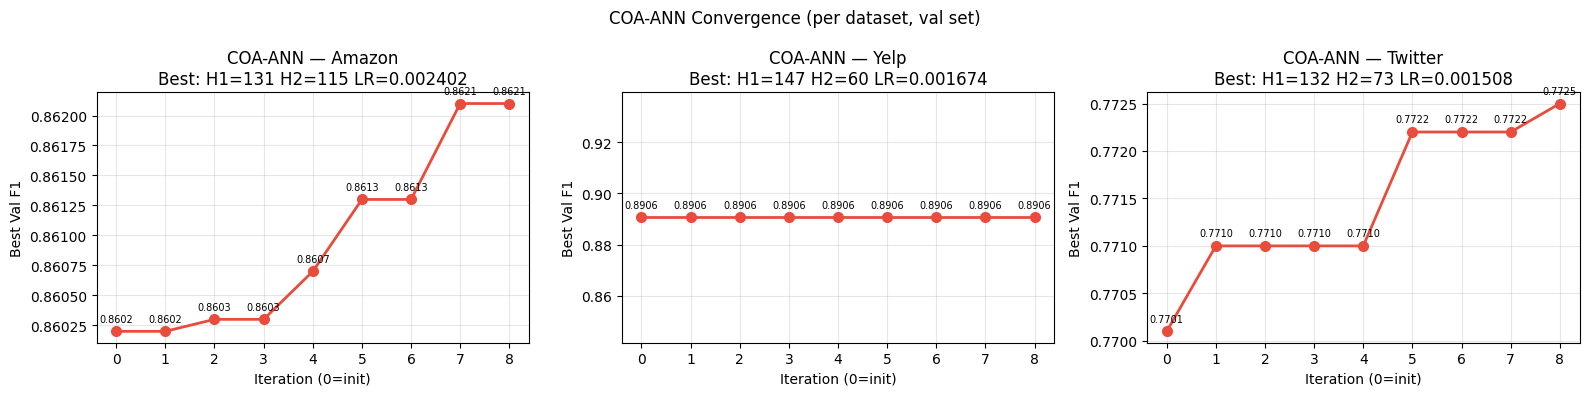


=== Summary ===
amazon    : H1=131  H2=115  LR=0.00240240  val_F1=0.8621
yelp      : H1=147  H2= 60  LR=0.00167381  val_F1=0.8906
twitter   : H1=132  H2= 73  LR=0.00150804  val_F1=0.7725


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, ds in zip(axes, DATASETS):
    r = coa_ann_results[ds]
    iters = r["convergence"]
    ax.plot(range(len(iters)), iters, "o-", color="#e74c3c", lw=2, ms=7)
    ax.set_title(f"COA-ANN — {ds.capitalize()}\n"
                 f"Best: H1={r['best_h1']} H2={r['best_h2']} LR={r['best_lr']:.6f}")
    ax.set_xlabel("Iteration (0=init)"); ax.set_ylabel("Best Val F1")
    ax.grid(alpha=0.3)
    for i,v in enumerate(iters):
        ax.annotate(f"{v:.4f}",(i,v),textcoords="offset points",xytext=(0,7),
                    ha="center",fontsize=7)
plt.suptitle("COA-ANN Convergence (per dataset, val set)", fontsize=12)
plt.tight_layout()
os.makedirs(f"{RESULTS_DIR}/global", exist_ok=True)
plt.savefig(f"{RESULTS_DIR}/global/fig_coa_ann_convergence.pdf", dpi=300, bbox_inches="tight")
plt.show()

print("\n=== Summary ===")
for ds, r in coa_ann_results.items():
    print(f"{ds:10s}: H1={r['best_h1']:3d}  H2={r['best_h2']:3d}  "
          f"LR={r['best_lr']:.8f}  val_F1={r['best_val_f1']:.4f}")
